# Copy number from single-cell DNA with HMMcopy

HMMcopy corrects the read depth of a genome for GC content and mappability and segments it into copy number states with a hidden Markov model (Ha et al., 2012).
The DLP+ pipeline runs it on every cell of a single-cell whole-genome sequencing run (Laks et al., 2019).
In this tutorial we load a pregrown tumor, sequence 400 of its cells with the DLP+ preset of the single-cell DNA (scDNA) assay, call copy number with HMMcopy and compare the calls with the true copy number of every cell and bin.
HMMcopy runs from its own conda environment, `iscc-hmmcopy`, which contains R and the Bioconductor package.
The notebook runs in about four minutes on a laptop.

In [1]:
%matplotlib inline
import os, tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iscc import pregrown
from iscc.tumor.viz import CNV_CMAP, cnv_norm
from iscc.sample import Resection
from iscc.data import scDNA
from iscc.data.human import HumanGenomeLayer
from iscc.integrations import biological_types, clones_from_clades

os.chdir(tempfile.mkdtemp())        # the data and the outputs of the tool go to a scratch directory

## Load a tumor

We load `cin`, one of the [pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors), a chromosomally unstable tumor of about 200,000 cancer cells on a 1 cm field, in which every cancer cell has a doubled genome and the clones differ mostly in copy number.
Its genome has one segment per chromosome arm, so that [`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/) can place every growth gene on its chromosome.

In [2]:
tumor = pregrown.cin()
print(f"{tumor.get_cancer_size():,} cancer cells of {tumor.get_tumor_size():,} cells after {tumor.time:.0f} generations")

200,156 cancer cells of 465,747 cells after 228 generations


## Sequence single cells

More than half of the cells of the resected specimen are normal cells.
Single-cell studies of carcinomas often enrich the dissociated cells for epithelial cells, and we model this enrichment with the recovery probabilities of the dissociation, which keep 5% of the stromal and immune cells.
We then sequence 400 cells with the DLP+ preset of the [`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/) assay, whose depth and dispersion [`estimate_dna`](https://pedrofale.github.io/iscc/reference/estimate_dna/) fitted to the DLP+ data set OV2295 (Laks et al., 2019).
DLP+ makes a library from each cell without whole-genome amplification, so its coverage is even, which the assay models with a high concentration `kappa` of the Dirichlet-multinomial depth.
DLP+ also images every well before sequencing, so we leave out doublets.
The [`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/) page lists the other presets, and [Shape the data](03_shape_the_data.ipynb) compares them.

In [3]:
specimen = Resection(tumor)
cells = specimen.dissociate(max_cells=4000, layers="scdna", recovery_probs={"stromal": 0.05, "immune": 0.05},
                            install=True, seed=0)
dna = scDNA(n_cells=400, platform="dlp", doublet_rate=0.0, seed=1).run(cells)

cell_type = pd.Series(biological_types(cells["cell_type"]["cell_id"]), index=cells["cell_type"].index)
print("dissociated cells:", cell_type.value_counts().to_dict())
print("sequenced cells:", cell_type[dna.cells].value_counts().to_dict())
print(f"{len(dna.genes):,} bins, {dna.coverage.values.mean():.0f} reads per bin on average")

dissociated cells: {'cancer': 1570, 'stromal': 120, 'epithelial': 76}
sequenced cells: {'cancer': 361, 'stromal': 24, 'epithelial': 15}
6,001 bins, 830 reads per bin on average


## The answer key

The assay returns the true copy number of every sequenced cell at every bin in `true_cn`.
We label each cancer cell with its clone, which is the clade of the true genealogy that contains the cell ([`clones_from_clades`](https://pedrofale.github.io/iscc/reference/clones_from_clades/)), and mark the cells whose genome is doubled.
Cancer cells above every clade share the label `other`.
We list the number of cells and of doubled cells in each group, and the mean copy number of its cells over the genome.

In [4]:
truth = dna.true_cn                                       # cells x bins
clone = clones_from_clades(tumor, min_cells=40).reindex(truth.index)
group = pd.Series(np.where(clone.isna(), "normal", clone.astype(str)), index=truth.index)
doubled = cells["cell_wgd"]["is_wgd"].reindex(truth.index)

pd.DataFrame({"cells": group.value_counts(), "doubled": doubled.groupby(group).sum(),
              "mean copy number": truth.mean(axis=1).groupby(group).mean().round(2)})

,cells,doubled,mean copy number
clone_1,44,44,3.70
clone_10,13,13,3.66
clone_11,15,15,3.75
clone_12,18,18,3.72
clone_13,12,12,3.69
clone_14,9,9,3.68
clone_15,14,14,3.66
clone_16,7,7,3.68
clone_2,39,39,3.71
clone_3,21,21,3.78


The run contains 361 cancer cells, of which 55 are above every clade and the others are in 16 clones, and 39 normal cells.
Every cancer cell has a doubled genome, and the mean copy number of each clone is between 3.6 and 3.8.

## Write the inputs of HMMcopy

HMMcopy reads the read count of every bin of a cell, with the GC content and the mappability of the bin.
Each growth gene covers a stretch of its chromosome arm, which [`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/) records, and we use these stretches as the bins.
We write the read counts with the writer of the assay and write the bin table, which needs chromosomes and positions, with pandas.

In [5]:
dna.write("hmmcopy", write_h5ad=False)                   # hmmcopy/coverage.csv, cells x bins
layer = HumanGenomeLayer(tumor)
stretch = layer.grid.set_index("growth_gene").sort_index()    # the stretch of its arm each growth gene covers
bins = pd.DataFrame({"chr": layer.reference.arms["chrom"].to_numpy()[stretch["arm"]],
                     "start": stretch["lo"].to_numpy() + 1, "end": stretch["hi"].to_numpy(),
                     "gc": dna.gc, "map": dna.mappability}, index=dna.genes)
bins.to_csv("hmmcopy/bins.csv", index=False)
print(f"{len(bins):,} bins on {bins['chr'].nunique()} chromosomes, of median length {(bins['end'] - bins['start']).median() / 1e3:,.0f} kb")

6,001 bins on 22 chromosomes, of median length 436 kb


## Run HMMcopy

The default parameters of HMMcopy are made for bulk tumor samples, and its six states start at quantiles of the depth of the sample, so the states rank segments rather than count copies.
We therefore use the single-cell parameters of the DLP+ pipeline, which fix twelve states at copy numbers 0 to 11.
The ploidy of a cell is unknown, so the pipeline segments the GC-corrected depth multiplied by 1 to 6, rescales each multiplier so that the states fit the depth, and keeps the multiplier at which the median depths of the segments are closest to whole copy numbers.
We follow the pipeline, except that we correct the depth with the `correctReadcount` function of HMMcopy at its default mappability cutoff of 0.9 and segment only the bins that it marks as ideal.

In [6]:
%%writefile hmmcopy/hmmcopy.R
# HMMcopy on every cell, with the single-cell parameters of the DLP+ pipeline (Laks et al. 2019)
suppressPackageStartupMessages({library(HMMcopy); library(data.table)})
reads <- fread("hmmcopy/coverage.csv")                   # one row per cell, one column per bin
bins <- fread("hmmcopy/bins.csv")
bins$chr <- factor(bins$chr, levels = unique(bins$chr))
cells <- reads[[1]]
reads <- as.matrix(reads[, -1])

# twelve states at copy number 0 to 11, on the linear scale of the corrected depth
param <- data.frame(strength = 1000, e = 0.999999, mu = 0:11, lambda = 20, nu = 2.1,
                    kappa = c(100, 100, 700, 100, rep(25, 8)), m = 0:11, eta = 50000,
                    gamma = 3, S = 1)
segment <- function(x, multiplier) {
  x$copy <- x$cor.gc * multiplier
  HMMsegment(x, param, maxiter = 200, verbose = FALSE)
}
# how far the median depth of each segment is from a whole copy number, as the pipeline scores it
halfiness <- function(x, seg) {
  state <- seg$state - 1
  median <- rep(seg$segs$median, rle(paste(x$chr, state))$lengths)
  sum((-log2(abs(pmin(abs(median - state), 0.499) - 0.5)) - 1) / (state + 1))
}

calls <- matrix(NA_integer_, length(cells), ncol(reads), dimnames = list(cells, colnames(reads)))
for (i in seq_along(cells)) {
  x <- correctReadcount(data.table(bins, reads = reads[i, ]), verbose = FALSE)
  ideal <- x$ideal & is.finite(x$cor.gc)
  x <- x[ideal]
  x$chr <- droplevels(x$chr)                              # a chromosome without reads has no bins left
  best <- Inf
  for (m in 1:6) {
    rough <- segment(x, m)$state - 1                      # rescale the multiplier so that the states fit the depth
    med <- tapply(x$cor.gc * m, rough, median)
    use <- names(med)[table(rough) > 200]
    fix <- mean(as.integer(use) / med[use])
    if (is.finite(fix)) m <- m * fix
    seg <- segment(x, m)
    state <- seg$state - 1
    score <- if (mean(state == 1) > 0.7) Inf else halfiness(x, seg)
    if (score < best) {
      best <- score
      calls[i, ideal] <- state
    }
  }
}
fwrite(as.data.table(calls, keep.rownames = "cell"), "hmmcopy/calls.csv")
cat(sprintf("called %d cells over %d bins\n", nrow(calls), ncol(calls)))

Writing hmmcopy/hmmcopy.R


In [7]:
!~/miniconda3/envs/iscc-hmmcopy/bin/Rscript hmmcopy/hmmcopy.R

called 400 cells over 6001 bins


## Score the calls

We compare the call at every bin with the true copy number, separately for the normal cells and the cancer cells, which in this tumor all have a doubled genome.
We report the fraction of bins with a call and the fraction of calls equal to the true copy number, averaged over the cells of each kind.

In [8]:
calls = pd.read_csv("hmmcopy/calls.csv", index_col="cell").reindex(index=truth.index, columns=truth.columns)
called = calls.notna()
correct = (calls == truth) & called
kind = pd.Series(np.where(group == "normal", "normal", np.where(doubled, "cancer, doubled", "cancer")),
                 index=truth.index)
per_cell = pd.DataFrame({"bins called": called.mean(axis=1),
                         "correct calls": correct.sum(axis=1) / called.sum(axis=1)})
print(f"bins with a mappability of at least 0.9: {(bins['map'] >= 0.9).mean():.0%}")
per_cell.groupby(kind).mean().assign(cells=kind.value_counts()).round(4)

bins with a mappability of at least 0.9: 61%


,bins called,correct calls,cells
"cancer, doubled",0.5951,0.4868,361
normal,0.5948,1.0000,39


For each cancer cell, we divide its mean true copy number over the called bins by its mean call, which gives the scale at which HMMcopy called the cell, and count the calls that are correct once we put them on the true scale of the cell.

In [9]:
cancer = kind.index[kind != "normal"]
scale = (truth.where(called).mean(axis=1) / calls.mean(axis=1))[cancer]
print("cancer cells by true over called copy number:", scale.round(1).value_counts().to_dict())
on_true_scale = calls.loc[cancer].mul(scale, axis=0).round()
print(f"calls correct on the true scale of each cancer cell: "
      f"{((on_true_scale == truth.loc[cancer]) & called.loc[cancer]).values.sum() / called.loc[cancer].values.sum():.1%}")

cancer cells by true over called copy number: {1.0: 179, 0.6: 81, 2.0: 48, 0.7: 34, 1.9: 17, 0.8: 2}


calls correct on the true scale of each cancer cell: 96.4%


We show the true copy number and the calls of every cell on the bins with a mappability of at least 0.9, with the cells grouped by clone and the bins without a call in gray.

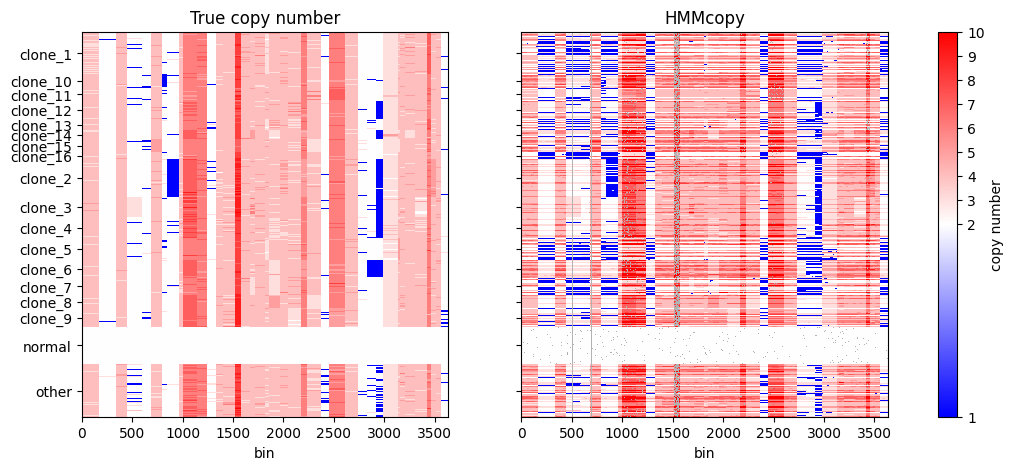

In [10]:
order = group.sort_values(kind="stable").index
mappable = bins.index[bins["map"] >= 0.9]
cmap = plt.get_cmap(CNV_CMAP).copy()
cmap.set_bad("0.7")                                       # bins without a call
norm = cnv_norm(truth.values)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, values, title in zip(axes, (truth, calls), ("True copy number", "HMMcopy")):
    im = ax.imshow(values.loc[order, mappable].values, aspect="auto", cmap=cmap, norm=norm, interpolation="none")
    ax.set(title=title, xlabel="bin")
sizes = group.value_counts().sort_index()
axes[0].set_yticks(sizes.cumsum() - sizes / 2, sizes.index)
fig.colorbar(im, ax=axes, label="copy number")
plt.show()

HMMcopy called about 60% of the bins of each cell and left the others without a call.
These are mostly the 39% of bins with a mappability below its cutoff of 0.9, together with the 0.5% of bins with the most reads of each cell, which `correctReadcount` marks as outliers and which fall on the segments with the highest copy number.
Every call in the normal cells was correct, while 49% of the calls in the cancer cells were.
HMMcopy called 179 of the 361 cancer cells at their true scale, 117 at 1.25 to 1.7 times their true copy number and 65 at about half of it.
Once we put the calls of each cell on its true scale, 96.4% of them are correct, so the calls are right up to the scale of each cell, and the ploidy is wrong in half of the cells.
Several multipliers can bring the segment medians of a cell close to whole copy numbers, a genome whose copy numbers are all even and its half for example, and the pipeline divides the halfiness of each bin by its state plus one, which may favor the higher multipliers.
In the heatmaps, the cancer cells called at the wrong scale are the rows whose calls are darker or lighter than their true copy number.

## Make the benchmark harder or easier

The settings of the assay and of the tumor change how hard this benchmark is, and [Shape the data](03_shape_the_data.ipynb) and [Shape the tumor](02_shape_the_tumor.ipynb) show their effects.
The settings of the tumor take effect when we grow a tumor from a configuration instead of loading a pregrown one.

- **Depth.** `mu_depth` sets the reads per bin, and with fewer reads the corrected depth is noisier.
- **Amplification.** A lower `kappa` models the uneven coverage of whole-genome amplification by MDA or MALBAC, as in the MDA-like setting of [Shape the data](03_shape_the_data.ipynb).
- **Doublets.** With a `doublet_rate` above 0 the assay merges pairs of cells into one library, whose depth mixes two genomes.
- **Copy number burden.** The copy number rate and the rate of genome doubling of the cancer cells (`mutation_rate`, `cnv_prob` and `wgd_rate` in `cell_params`) set how many copy number states and doubled cells there are to call.
- **Purity of the run.** The recovery probabilities of the dissociation set how many normal cells the run contains.

The [`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/), [`DNABatchHyperParams`](https://pedrofale.github.io/iscc/reference/DNABatchHyperParams/) and [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) pages document every parameter.